--- 1. FETCHING DATASETS ---
--- 2. BUILDING SPATIAL & TEMPORAL FEATURES ---

--- 3. EVALUATING MODEL A (HOURLY HAZARD PREDICTION) ---
Fold   | Base Rate    | PR-AUC       | Lift over Dummy
----------------------------------------------------
Fold 1  | 0.0595       | 0.1419       | 2.38x
Fold 2  | 0.0476       | 0.0609       | 1.28x
Fold 3  | 0.0774       | 0.1052       | 1.36x
Fold 4  | 0.0982       | 0.1757       | 1.79x
Fold 5  | 0.1042       | 0.2415       | 2.32x
Average Lift over Dummy Baseline: 1.83x

--- 4. BUILDING MODEL B (NIGHTLY RISK PREDICTOR) ---
Nightly Model (Last 30 Days Holdout): Base Rate = 0.833 | PR-AUC = 1.000 | Lift = 1.20x


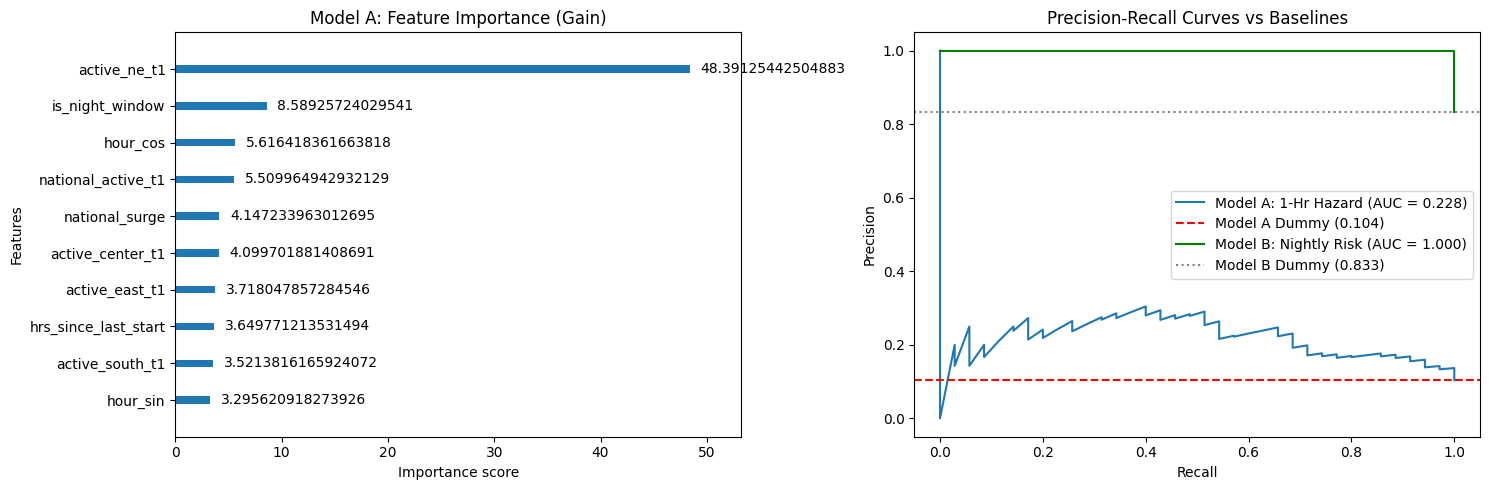

In [1]:
import os
import requests
import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score, classification_report
from sklearn.model_selection import TimeSeriesSplit

# =============================================================================
# 1. DATA ACQUISITION & TIMEZONE LOCALIZATION
# =============================================================================
print("--- 1. FETCHING DATASETS ---")
def download_vadimkin_dataset(output_path="data/raw_official_alerts.csv"):
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    api_url = "https://api.github.com/repos/Vadimkin/ukrainian-air-raid-sirens-dataset/contents/datasets"
    res = requests.get(api_url, timeout=15).json()
    target_url = next((f["download_url"] for f in res if "official" in f["name"].lower()), res[0]["download_url"])
    with open(output_path, "wb") as f:
        f.write(requests.get(target_url, timeout=30).content)
    return output_path

RAW_CSV_PATH = download_vadimkin_dataset()

df = pd.read_csv(RAW_CSV_PATH)
df['started_at'] = pd.to_datetime(df['started_at'], errors='coerce', utc=True).dt.tz_convert('Europe/Kyiv').dt.tz_localize(None)
df['finished_at'] = pd.to_datetime(df['finished_at'], errors='coerce', utc=True).dt.tz_convert('Europe/Kyiv').dt.tz_localize(None)

is_kyiv_city = df['oblast'].astype(str).str.contains("Kyiv|Київ", case=False, na=False) & ~df['oblast'].astype(str).str.contains("oblast|область", case=False, na=False)
kyiv_df = df[is_kyiv_city].dropna(subset=['started_at', 'finished_at']).sort_values('started_at')
df_oblast = df[df['level'] == 'oblast'].copy()

# Filter timeline starting 2024
min_time = pd.to_datetime("2024-01-01")
max_time = kyiv_df['finished_at'].max().ceil("h")
time_grid = pd.date_range(start=min_time, end=max_time, freq="1h")

def hourly_active_mask(df_sub, grid):
    s = pd.Series(0, index=grid)
    for st, en in zip(df_sub['started_at'], df_sub['finished_at']):
        if pd.notna(st) and pd.notna(en):
            s.loc[st.floor("h"):en.floor("h")] = 1
    return s

kyiv_active = hourly_active_mask(kyiv_df[kyiv_df['started_at'] >= min_time], time_grid)
kyiv_starts = kyiv_df[kyiv_df['started_at'] >= min_time].set_index("started_at").resample("1h").size().reindex(time_grid, fill_value=0)
target_onset = (kyiv_starts > 0).astype(int)

ts_df = pd.DataFrame({"target": target_onset, "kyiv_active": kyiv_active}, index=time_grid)
ts_df["kyiv_active_prev"] = ts_df["kyiv_active"].shift(1)

# =============================================================================
# 2. FEATURE ENGINEERING (MODEL A: HOURLY HAZARD)
# =============================================================================
print("--- 2. BUILDING SPATIAL & TEMPORAL FEATURES ---")

# A) Regional Spatial Clusters
clusters = {
    "ne": ["Sumy", "Kharkiv", "Chernihiv", "Poltava"],
    "south": ["Odesa", "Mykolaiv", "Kherson", "Kirovohrad"],
    "east": ["Dnipropetrovsk", "Zaporizhia", "Donetsk"],
    "center": ["Cherkasy", "Zhytomyr", "Vinnytsia"]
}

for name, obl_list in clusters.items():
    mask = df_oblast['oblast'].astype(str).apply(lambda x: any(v.lower() in x.lower() for v in obl_list))
    sub = df_oblast[mask]
    act = pd.DataFrame(index=time_grid)
    for obl in sub['oblast'].unique():
        act[obl] = hourly_active_mask(sub[sub['oblast'] == obl], time_grid)
    ts_df[f"active_{name}_t1"] = act.sum(axis=1).shift(1)

# B) Nationwide Intensity & Acceleration
all_oblasts = pd.DataFrame(index=time_grid)
for obl in df_oblast['oblast'].dropna().unique():
    all_oblasts[obl] = hourly_active_mask(df_oblast[df_oblast['oblast'] == obl], time_grid)

ts_df["national_active_t1"] = all_oblasts.sum(axis=1).shift(1)
ts_df["national_active_t2"] = all_oblasts.sum(axis=1).shift(2)
ts_df["national_surge"] = ts_df["national_active_t1"] - ts_df["national_active_t2"]

# C) Temporal & Recency Dynamics
n = len(ts_df)
pos = pd.Series(np.where(ts_df["target"] > 0, np.arange(n), np.nan), index=ts_df.index).ffill()
ts_df["hrs_since_last_start"] = (np.arange(n) - pos).shift(1)
ts_df["alerts_last_24h"] = ts_df["target"].shift(1).rolling(24).sum()
ts_df["alerts_last_7d"] = ts_df["target"].shift(1).rolling(168).sum()

# Night window feature (22:00 to 06:00)
ts_df["is_night_window"] = ts_df.index.hour.isin([22, 23, 0, 1, 2, 3, 4, 5, 6]).astype(int)
ts_df["hour_sin"] = np.sin(2 * np.pi * ts_df.index.hour / 24.0)
ts_df["hour_cos"] = np.cos(2 * np.pi * ts_df.index.hour / 24.0)
ts_df["dayofweek"] = ts_df.index.dayofweek

ts_df = ts_df.dropna()

# CRITICAL LEAKAGE FILTER: Predict ONLY when Kyiv was NOT active in t-1
hazard_df = ts_df[ts_df["kyiv_active_prev"] == 0].copy()

feature_cols = [
    "active_ne_t1", "active_south_t1", "active_east_t1", "active_center_t1",
    "national_active_t1", "national_surge", "hrs_since_last_start",
    "alerts_last_24h", "alerts_last_7d", "is_night_window",
    "hour_sin", "hour_cos", "dayofweek"
]

X = hazard_df[feature_cols]
y = hazard_df["target"]

# =============================================================================
# 3. EVALUATION: MODEL A (1-HOUR HAZARD ONSET)
# =============================================================================
print("\n--- 3. EVALUATING MODEL A (HOURLY HAZARD PREDICTION) ---")
tscv = TimeSeriesSplit(n_splits=5, test_size=24*14, gap=24)

print(f"{'Fold':<6} | {'Base Rate':<12} | {'PR-AUC':<12} | {'Lift over Dummy'}")
print("-" * 52)

lifts = []
for i, (tr_idx, te_idx) in enumerate(tscv.split(X)):
    X_tr, y_tr = X.iloc[tr_idx], y.iloc[tr_idx]
    X_te, y_te = X.iloc[te_idx], y.iloc[te_idx]

    m = xgb.XGBClassifier(n_estimators=250, learning_rate=0.03, max_depth=4, random_state=42, eval_metric="logloss")
    m.fit(X_tr, y_tr)

    p_te = m.predict_proba(X_te)[:, 1]
    auc = average_precision_score(y_te, p_te)
    base = y_te.mean()
    lift = auc / max(base, 1e-9)
    lifts.append(lift)
    print(f"Fold {i+1:<2} | {base:<12.4f} | {auc:<12.4f} | {lift:.2f}x")

print(f"Average Lift over Dummy Baseline: {np.mean(lifts):.2f}x")

# Final Fold Train & Plot
final_m = xgb.XGBClassifier(n_estimators=250, learning_rate=0.03, max_depth=4, random_state=42)
final_m.fit(X.iloc[:-24*14], y.iloc[:-24*14])

X_test_final, y_test_final = X.iloc[-24*14:], y.iloc[-24*14:]
p_final_a = final_m.predict_proba(X_test_final)[:, 1]

# =============================================================================
# 4. MODEL B: NIGHTLY ATTACK RISK PREDICTOR (DAY-AHEAD)
# =============================================================================
print("\n--- 4. BUILDING MODEL B (NIGHTLY RISK PREDICTOR) ---")

# Aggregate into Daily Night-Windows (22:00 to 07:00 next morning)
ts_df['date_group'] = (ts_df.index - pd.Timedelta(hours=7)).date
daily_df = ts_df.groupby('date_group').agg(
    night_alert_occurred=('target', lambda x: int(x.sum() > 0)),
    prev_24h_alerts=('alerts_last_24h', 'last'),
    prev_7d_alerts=('alerts_last_7d', 'last'),
    national_intensity=('national_active_t1', 'mean'),
    hrs_since_last=('hrs_since_last_start', 'last'),
    day_of_week=('dayofweek', 'last')
).dropna()

X_b = daily_df[["prev_24h_alerts", "prev_7d_alerts", "national_intensity", "hrs_since_last", "day_of_week"]]
y_b = daily_df["night_alert_occurred"]

tscv_b = TimeSeriesSplit(n_splits=5, test_size=30)
mb = xgb.XGBClassifier(n_estimators=150, learning_rate=0.03, max_depth=3, random_state=42)

# Train on historical days, evaluate on last 30 days
mb.fit(X_b.iloc[:-30], y_b.iloc[:-30])
p_final_b = mb.predict_proba(X_b.iloc[-30:])[:, 1]
auc_b = average_precision_score(y_b.iloc[-30:], p_final_b)
base_b = y_b.iloc[-30:].mean()

print(f"Nightly Model (Last 30 Days Holdout): Base Rate = {base_b:.3f} | PR-AUC = {auc_b:.3f} | Lift = {auc_b/base_b:.2f}x")

# =============================================================================
# 5. VISUALIZATIONS FOR SUBMISSION
# =============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Feature Importance (Model A)
xgb.plot_importance(final_m, importance_type='gain', max_num_features=10, ax=ax1, title="Model A: Feature Importance (Gain)")
ax1.grid(False)

# Plot 2: PR Curve Comparison
pr_a, rc_a, _ = precision_recall_curve(y_test_final, p_final_a)
pr_b, rc_b, _ = precision_recall_curve(y_b.iloc[-30:], p_final_b)

ax2.plot(rc_a, pr_a, label=f"Model A: 1-Hr Hazard (AUC = {average_precision_score(y_test_final, p_final_a):.3f})")
ax2.axhline(y_test_final.mean(), color='r', linestyle='--', label=f"Model A Dummy ({y_test_final.mean():.3f})")

ax2.plot(rc_b, pr_b, label=f"Model B: Nightly Risk (AUC = {auc_b:.3f})", color='green')
ax2.axhline(base_b, color='gray', linestyle=':', label=f"Model B Dummy ({base_b:.3f})")

ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.set_title("Precision-Recall Curves vs Baselines")
ax2.legend()

plt.tight_layout()
plt.show()

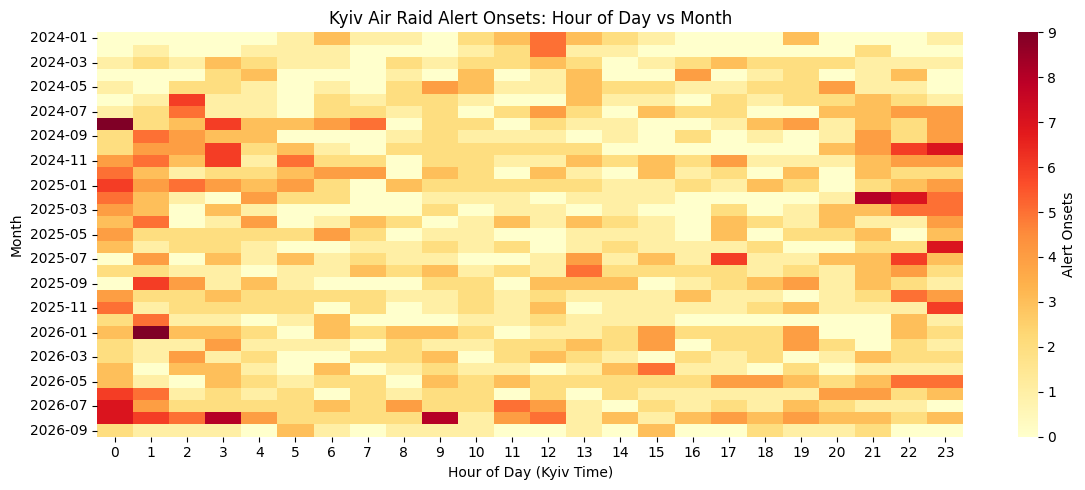

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Extract month and hour from the dataset
ts_df['month'] = ts_df.index.to_period('M')
heatmap_data = ts_df.groupby(['month', ts_df.index.hour])['target'].sum().unstack()

plt.figure(figsize=(12, 5))
sns.heatmap(heatmap_data, cmap="YlOrRd", cbar_kws={'label': 'Alert Onsets'})
plt.title("Kyiv Air Raid Alert Onsets: Hour of Day vs Month")
plt.xlabel("Hour of Day (Kyiv Time)")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

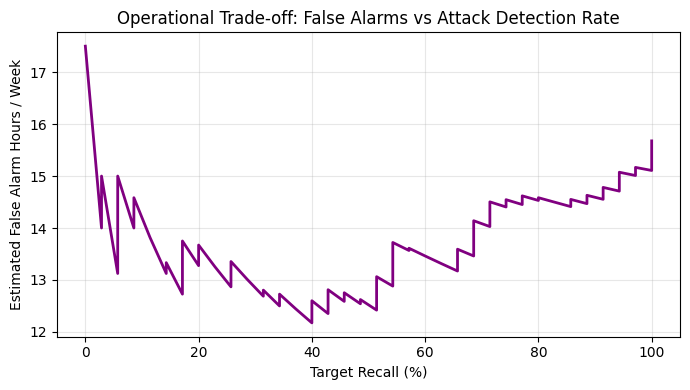

In [6]:
from sklearn.metrics import precision_recall_curve

pr, rc, th = precision_recall_curve(y_test_final, p_final_a)
# Convert false positives to approximate false alarm hours per week
fp_hours_per_week = ((1 - pr[:-1]) * (24 * 7 * y_test_final.mean()))

plt.figure(figsize=(7, 4))
plt.plot(rc[:-1] * 100, fp_hours_per_week, color="purple", linewidth=2)
plt.xlabel("Target Recall (%)")
plt.ylabel("Estimated False Alarm Hours / Week")
plt.title("Operational Trade-off: False Alarms vs Attack Detection Rate")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()